# 01 — Data Loading & Integrity Check
### Diabetic Foot Thermography Project — Phase 2

**Purpose of this notebook.** This is the first executable step of the project. It builds a
complete, queryable **file manifest** of the raw dataset, runs a set of **integrity checks**
against the known expected structure, cleans the messy Excel **metadata** file into a usable
table, and **cross-validates** the raw pixel data against the metadata's pre-computed averages
to confirm the two sources agree with each other.

This notebook is meant to be read as documentation, not just executed once. Every section has
a markdown cell explaining *what* it does and *why*, and every check prints a clearly labeled
pass/fail result so the output can be copied elsewhere for review.

**Dataset:** *Plantar Thermogram Database for the Study of Diabetic Foot Complications*
(Hernández-Contreras et al., IEEE Access, 2019). 167 subjects (45 Control, 122 DM), 10 CSV +
10 PNG files per subject, two full-foot files (L/R) and eight angiosome mask files
(4 regions × 2 feet) per subject.

**Known issue going in:** the dataset has 1671 PNGs on disk vs. an expected 1670 — this
notebook's job is to locate that anomaly precisely, not just note that it exists.


## 1. Setup

Only two paths should ever need to change when moving this notebook to another machine:
`ROOT_PATH` (the dataset root) and `METADATA_PATH` (the Excel file). Everything else is
derived from these two variables or from the data itself.

We keep dependencies to the minimum requested: `pandas`, `numpy`, `pathlib`, and
`matplotlib`. `re` is part of the standard library and is used only for filename parsing.

`integrity_issues` is a running list that every later section appends to whenever it finds a
problem. Section 9 prints it in full as part of the final summary, so nothing found along the
way gets silently lost.


In [4]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- The only two things that should need to change on another machine ---
ROOT_PATH = Path(r"C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase")
METADATA_PATH = Path(r"C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase\Plantar Thermogram Database.xlsx")

# Where processed outputs (manifest.csv, subject_metadata.csv) are written
OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Running log of every integrity problem found anywhere in this notebook.
# Section 9 prints this in full — nothing found along the way gets lost.
integrity_issues = []

EXPECTED_COUNTS = {"Control": 45, "DM": 122}
EXPECTED_TOTAL_SUBJECTS = sum(EXPECTED_COUNTS.values())
EXPECTED_FILES_PER_SUBJECT = 10  # per file type (10 CSV + 10 PNG)
REGIONS = ["LCA", "LPA", "MCA", "MPA"]

print("ROOT_PATH     :", ROOT_PATH)
print("METADATA_PATH :", METADATA_PATH)
print("OUTPUT_DIR    :", OUTPUT_DIR.resolve())
print("ROOT_PATH exists:", ROOT_PATH.exists())
print("METADATA_PATH exists:", METADATA_PATH.exists())


ROOT_PATH     : C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase
METADATA_PATH : C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase\Plantar Thermogram Database.xlsx
OUTPUT_DIR    : C:\workstation\3RD YEAR\Diabetic_Foot\data\processed
ROOT_PATH exists: True
METADATA_PATH exists: True


## 2. File Manifest Builder

We walk `Control Group/` and `DM Group/` and, for every CSV/PNG we find, parse out the fields
we'll need throughout the rest of the project: which group and subject it belongs to, which
foot, whether it's a full-foot file or an angiosome mask, and which angiosome region if so.

**Why filename parsing is done the way it is:** rather than assuming gender is always embedded
in the filename, we read `subject_id` and `gender` from the **subject folder name**
(`{SUBJECT}_{GENDER}`, e.g. `CG001_M`) — that pattern is guaranteed by the dataset structure.
The `foot_side` and `region` are then pulled from the **end of the filename** with a regex
that matches `..._L`, `..._R`, `..._L_LCA`, `..._R_MPA`, etc. This is robust to filenames with
or without the gender segment repeated in them, since we only anchor on the trailing tokens.

Any subject folder or filename that doesn't match the expected pattern is recorded rather than
silently skipped — check `integrity_issues` and the printed warnings below if that happens.


In [5]:
SUBJECT_FOLDER_RE = re.compile(r'^(?P<subject>[A-Za-z]{2}\d+)_(?P<gender>[MF])$')
FILENAME_RE = re.compile(r'_(?P<side>[LR])(?:_(?P<region>LCA|LPA|MCA|MPA))?$')

GROUP_DIRS = {
    "Control": ROOT_PATH / "Control Group",
    "DM": ROOT_PATH / "DM Group",
}

records = []
unparsed_subject_folders = []
unparsed_files = []

for group_name, group_dir in GROUP_DIRS.items():
    if not group_dir.exists():
        print(f"WARNING: expected group directory not found: {group_dir}")
        continue

    for subject_dir in sorted(p for p in group_dir.iterdir() if p.is_dir()):
        m = SUBJECT_FOLDER_RE.match(subject_dir.name)
        if not m:
            unparsed_subject_folders.append(str(subject_dir))
            continue
        subject_id = m.group("subject")
        gender = m.group("gender")

        for file in subject_dir.rglob("*"):
            if not file.is_file():
                continue
            if file.suffix.lower() not in (".csv", ".png"):
                continue

            is_angiosome = file.parent.name == "Angiosoms"
            fm = FILENAME_RE.search(file.stem)
            if fm:
                side = fm.group("side")
                region = fm.group("region")
            else:
                side, region = None, None
                unparsed_files.append(str(file))

            records.append({
                "group": group_name,
                "subject_id": subject_id,
                "gender": gender,
                "foot_side": side,
                "is_angiosome": is_angiosome,
                "region": region,
                "file_type": file.suffix.lower().lstrip("."),
                "file_stem": file.stem,
                "file_path": str(file),
            })

manifest_df = pd.DataFrame.from_records(records)

manifest_path = OUTPUT_DIR / "manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

print("=== FILE MANIFEST BUILT ===")
print(f"manifest_df shape: {manifest_df.shape}")
print(f"Saved to: {manifest_path.resolve()}")

if unparsed_subject_folders:
    integrity_issues.append(f"Subject folders that did not match expected naming pattern: {unparsed_subject_folders}")
    print(f"WARNING: {len(unparsed_subject_folders)} subject folder(s) did not match the expected naming pattern:")
    for f in unparsed_subject_folders:
        print("   ", f)

if unparsed_files:
    integrity_issues.append(f"Files whose side/region could not be parsed from the filename: {unparsed_files}")
    print(f"WARNING: {len(unparsed_files)} file(s) had a filename that did not match the expected pattern:")
    for f in unparsed_files:
        print("   ", f)

manifest_df.head()


=== FILE MANIFEST BUILT ===
manifest_df shape: (3340, 9)
Saved to: C:\workstation\3RD YEAR\Diabetic_Foot\data\processed\manifest.csv


,group,subject_id,gender,foot_side,is_angiosome,region,file_type,file_stem,file_path
0,Control,CG001,M,L,False,NaN,csv,CG001_M_L,C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDa...
1,Control,CG001,M,L,False,NaN,png,CG001_M_L,C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDa...
2,Control,CG001,M,R,False,NaN,csv,CG001_M_R,C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDa...
3,Control,CG001,M,R,False,NaN,png,CG001_M_R,C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDa...
4,Control,CG001,M,L,True,LCA,csv,CG001_M_L_LCA,C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDa...


## 3. Integrity Checks

Four checks, run in order, each printing an explicit pass/fail result rather than just
computing a number silently. Check 3b is the one expected to surface the known "1671 vs 1670
PNGs" anomaly — when it does, it prints the exact subject and its full file list so the extra
file can be identified precisely.


### 3a. Subject counts per group

Confirms 45 Control subjects, 122 DM subjects, 167 total — based on the subject folders
actually discovered while building the manifest.


In [6]:
print("=== INTEGRITY CHECK: Subject Counts ===")

subject_counts = manifest_df.groupby("group")["subject_id"].nunique()
total_subjects = manifest_df["subject_id"].nunique()

for group, expected in EXPECTED_COUNTS.items():
    actual = int(subject_counts.get(group, 0))
    status = "PASS" if actual == expected else "FAIL"
    print(f"[{status}] {group} Group: found {actual} subjects (expected {expected})")
    if actual != expected:
        integrity_issues.append(f"Subject count mismatch in {group} Group: found {actual}, expected {expected}")

status_total = "PASS" if total_subjects == EXPECTED_TOTAL_SUBJECTS else "FAIL"
print(f"[{status_total}] Total: found {total_subjects} subjects (expected {EXPECTED_TOTAL_SUBJECTS})")
if total_subjects != EXPECTED_TOTAL_SUBJECTS:
    integrity_issues.append(f"Total subject count mismatch: found {total_subjects}, expected {EXPECTED_TOTAL_SUBJECTS}")


=== INTEGRITY CHECK: Subject Counts ===
[PASS] Control Group: found 45 subjects (expected 45)
[PASS] DM Group: found 122 subjects (expected 122)
[PASS] Total: found 167 subjects (expected 167)


### 3b. Exactly 10 CSV + 10 PNG per subject

Any subject that deviates gets its exact file counts and its **full file list** printed, so an
anomaly like an extra or misplaced file can be pinpointed rather than just flagged as "off".


In [7]:
print("=== INTEGRITY CHECK: File Counts per Subject ===")

file_counts = (
    manifest_df.groupby(["group", "subject_id", "file_type"])
    .size()
    .unstack(fill_value=0)
)
for col in ("csv", "png"):
    if col not in file_counts.columns:
        file_counts[col] = 0

deviations = file_counts[
    (file_counts["csv"] != EXPECTED_FILES_PER_SUBJECT) |
    (file_counts["png"] != EXPECTED_FILES_PER_SUBJECT)
]

if deviations.empty:
    print(f"[PASS] Every subject has exactly {EXPECTED_FILES_PER_SUBJECT} CSV and {EXPECTED_FILES_PER_SUBJECT} PNG files.")
else:
    print(f"[FAIL] {len(deviations)} subject(s) deviate from the expected {EXPECTED_FILES_PER_SUBJECT}/{EXPECTED_FILES_PER_SUBJECT} CSV/PNG count:")
    for (group, subject_id), row in deviations.iterrows():
        csv_n, png_n = int(row["csv"]), int(row["png"])
        print(f"\n   --- {subject_id} ({group} Group): csv={csv_n}, png={png_n} ---")
        sub_files = manifest_df[
            (manifest_df["group"] == group) & (manifest_df["subject_id"] == subject_id)
        ].sort_values(["is_angiosome", "file_type", "file_stem"])
        for _, r in sub_files.iterrows():
            print(f"      [{r['file_type']}] {r['file_path']}")
        integrity_issues.append(
            f"{subject_id} ({group}): csv={csv_n}, png={png_n} "
            f"(expected {EXPECTED_FILES_PER_SUBJECT}/{EXPECTED_FILES_PER_SUBJECT})"
        )


=== INTEGRITY CHECK: File Counts per Subject ===
[PASS] Every subject has exactly 10 CSV and 10 PNG files.


### 3c. Every CSV has a matching PNG and vice versa

Matches files by base filename (stem) within each subject. Any file present in one format but
not the other is reported as an orphan.


In [8]:
print("=== INTEGRITY CHECK: CSV <-> PNG Matching ===")

pivot = manifest_df.pivot_table(
    index=["group", "subject_id", "file_stem"],
    columns="file_type",
    values="file_path",
    aggfunc="first",
)
for col in ("csv", "png"):
    if col not in pivot.columns:
        pivot[col] = np.nan

orphan_csv = pivot[pivot["png"].isna()]
orphan_png = pivot[pivot["csv"].isna()]

if orphan_csv.empty and orphan_png.empty:
    print("[PASS] Every CSV has a matching PNG and every PNG has a matching CSV.")
else:
    if not orphan_csv.empty:
        stems = orphan_csv.index.get_level_values("file_stem").tolist()
        print(f"[FAIL] {len(orphan_csv)} CSV file(s) have no matching PNG:")
        for stem, path in zip(stems, orphan_csv["csv"]):
            print(f"    {stem}  ->  {path}")
        integrity_issues.append(f"Orphaned CSVs with no matching PNG: {stems}")
    if not orphan_png.empty:
        stems = orphan_png.index.get_level_values("file_stem").tolist()
        print(f"[FAIL] {len(orphan_png)} PNG file(s) have no matching CSV:")
        for stem, path in zip(stems, orphan_png["png"]):
            print(f"    {stem}  ->  {path}")
        integrity_issues.append(f"Orphaned PNGs with no matching CSV: {stems}")


=== INTEGRITY CHECK: CSV <-> PNG Matching ===
[PASS] Every CSV has a matching PNG and every PNG has a matching CSV.


### 3d. Angiosome files are grouped correctly

For every subject, both feet should have all four angiosome regions (LCA, LPA, MCA, MPA)
present. This is a slightly stricter check than 3b/3c: it confirms not just a *count* of 8
angiosome files per subject, but that the *right 4 regions* exist for *each* foot.


In [9]:
print("=== INTEGRITY CHECK: Angiosome Region Grouping ===")

expected_regions = set(REGIONS)
angiosome_rows = manifest_df[manifest_df["is_angiosome"]]

region_groups = (
    angiosome_rows[angiosome_rows["file_type"] == "csv"]
    .groupby(["group", "subject_id", "foot_side"])["region"]
    .apply(lambda s: set(s.dropna()))
)

bad_groups = region_groups[region_groups != expected_regions]

if bad_groups.empty:
    print(f"[PASS] Every subject has all 4 angiosome regions ({', '.join(REGIONS)}) present for both feet.")
else:
    print(f"[FAIL] {len(bad_groups)} (subject, foot) combination(s) are missing angiosome regions:")
    for (group, subject_id, side), found in bad_groups.items():
        missing = expected_regions - found
        extra = found - expected_regions
        print(f"    {subject_id} ({group}, {side} foot): found {sorted(found)}, missing {sorted(missing)}, unexpected {sorted(extra)}")
        integrity_issues.append(
            f"{subject_id} ({group}, {side} foot): missing angiosome regions {sorted(missing)}"
        )


=== INTEGRITY CHECK: Angiosome Region Grouping ===
[PASS] Every subject has all 4 angiosome regions (LCA, LPA, MCA, MPA) present for both feet.


## 4. Raw CSV Shape Analysis

Grid dimensions vary between subjects **and between the two feet of the same subject**, so no
fixed shape is ever assumed. This section loads every full-foot CSV (334 expected: 167
subjects × 2 feet), records its `(height, width)`, and summarizes the distribution — this
summary is what will drive resizing/padding decisions in the next phase of the project.


=== RAW CSV SHAPE ANALYSIS ===
Full-foot CSV files found: 334 (expected 334)

--- Shape summary (all full-foot files) ---
            height      width
min     103.000000  41.000000
max     200.000000  88.000000
mean    149.335329  64.482036
median  148.500000  65.000000


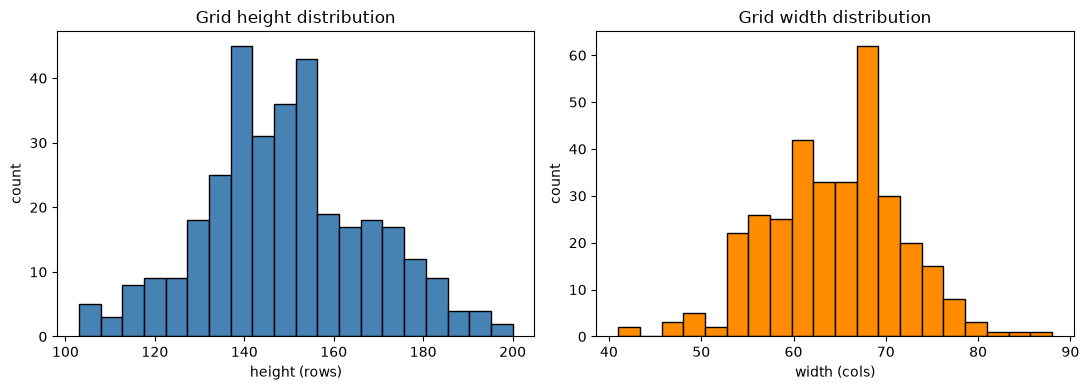

In [10]:
print("=== RAW CSV SHAPE ANALYSIS ===")

full_foot_csv = manifest_df[
    (manifest_df["file_type"] == "csv") & (~manifest_df["is_angiosome"])
]
print(f"Full-foot CSV files found: {len(full_foot_csv)} (expected {EXPECTED_TOTAL_SUBJECTS * 2})")

shape_records = []
load_errors = []
for _, row in full_foot_csv.iterrows():
    try:
        arr = np.loadtxt(row["file_path"], delimiter=",")
    except Exception as e:
        load_errors.append((row["file_path"], str(e)))
        continue
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)
    shape_records.append({
        "group": row["group"],
        "subject_id": row["subject_id"],
        "foot_side": row["foot_side"],
        "height": arr.shape[0],
        "width": arr.shape[1],
    })

if load_errors:
    integrity_issues.append(f"CSV files that failed to load: {load_errors}")
    print(f"WARNING: {len(load_errors)} file(s) failed to load:")
    for path, err in load_errors:
        print(f"    {path}: {err}")

shape_df = pd.DataFrame(shape_records)

print("\n--- Shape summary (all full-foot files) ---")
summary = shape_df[["height", "width"]].agg(["min", "max", "mean", "median"])
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(shape_df["height"], bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("Grid height distribution")
axes[0].set_xlabel("height (rows)")
axes[0].set_ylabel("count")

axes[1].hist(shape_df["width"], bins=20, color="darkorange", edgecolor="black")
axes[1].set_title("Grid width distribution")
axes[1].set_xlabel("width (cols)")
axes[1].set_ylabel("count")

plt.tight_layout()
plt.show()


## 5. Angiosome Mask Validation

For a random sample of at least 10 subjects (both feet), confirms that each angiosome CSV is:

1. **The same shape** as its parent full-foot CSV, and
2. **A true subset/mask** of the full-foot data — every nonzero pixel in the angiosome CSV is
   also nonzero at the same coordinate in the parent CSV.

This is what lets the angiosome-graph design build nodes directly from the full-foot grid
using known per-region masks, without separate spatial registration.


In [11]:
print("=== ANGIOSOME MASK VALIDATION ===")

rng = np.random.default_rng(42)
all_subjects = manifest_df["subject_id"].unique()
n_sample = min(10, len(all_subjects))
sample_subjects = rng.choice(all_subjects, size=n_sample, replace=False)
print(f"Sampled {n_sample} subjects: {sorted(sample_subjects)}")

mask_results = []
for subject_id in sample_subjects:
    for side in ["L", "R"]:
        full_row = manifest_df[
            (manifest_df["subject_id"] == subject_id)
            & (manifest_df["foot_side"] == side)
            & (~manifest_df["is_angiosome"])
            & (manifest_df["file_type"] == "csv")
        ]
        if full_row.empty:
            mask_results.append((subject_id, side, "N/A", "MISSING FULL-FOOT FILE", None))
            continue
        full_arr = np.loadtxt(full_row.iloc[0]["file_path"], delimiter=",")

        for region in REGIONS:
            ang_row = manifest_df[
                (manifest_df["subject_id"] == subject_id)
                & (manifest_df["foot_side"] == side)
                & (manifest_df["region"] == region)
                & (manifest_df["file_type"] == "csv")
            ]
            if ang_row.empty:
                mask_results.append((subject_id, side, region, False, None))
                continue

            ang_arr = np.loadtxt(ang_row.iloc[0]["file_path"], delimiter=",")
            shape_ok = ang_arr.shape == full_arr.shape
            if shape_ok:
                nonzero = ang_arr != 0
                subset_ok = bool(np.all(full_arr[nonzero] != 0)) if nonzero.any() else True
            else:
                subset_ok = None  # can't compare pixel-by-pixel if shapes differ
            mask_results.append((subject_id, side, region, shape_ok, subset_ok))

mask_df = pd.DataFrame(mask_results, columns=["subject_id", "side", "region", "shape_ok", "subset_ok"])
print(mask_df.to_string(index=False))

shape_failures = mask_df[mask_df["shape_ok"] != True]
subset_failures = mask_df[mask_df["subset_ok"] == False]

if shape_failures.empty and subset_failures.empty:
    print("\n[PASS] All sampled angiosome CSVs match their parent's shape and are true pixel subsets.")
else:
    if not shape_failures.empty:
        print(f"\n[FAIL] {len(shape_failures)} angiosome file(s) failed the shape check:")
        print(shape_failures.to_string(index=False))
        integrity_issues.append(f"Angiosome shape mismatches: {shape_failures.to_dict('records')}")
    if not subset_failures.empty:
        print(f"\n[FAIL] {len(subset_failures)} angiosome file(s) are not a true subset of their parent:")
        print(subset_failures.to_string(index=False))
        integrity_issues.append(f"Angiosome subset-mask failures: {subset_failures.to_dict('records')}")


=== ANGIOSOME MASK VALIDATION ===
Sampled 10 subjects: ['CG015', 'CG016', 'CG034', 'DM026', 'DM060', 'DM071', 'DM079', 'DM095', 'DM117', 'DM119']
subject_id side region  shape_ok  subset_ok
     DM119    L    LCA      True       True
     DM119    L    LPA      True       True
     DM119    L    MCA      True       True
     DM119    L    MPA      True       True
     DM119    R    LCA      True       True
     DM119    R    LPA      True       True
     DM119    R    MCA      True       True
     DM119    R    MPA      True       True
     DM079    L    LCA      True       True
     DM079    L    LPA      True       True
     DM079    L    MCA      True       True
     DM079    L    MPA      True       True
     DM079    R    LCA      True       True
     DM079    R    LPA      True       True
     DM079    R    MCA      True       True
     DM079    R    MPA      True       True
     CG015    L    LCA      True       True
     CG015    L    LPA      True       True
     CG015    L   

## 6. Metadata Cleaning

The Excel file's true header spans **two rows**: row 1 has top-level labels (`Subject`,
`Gender`, ..., `RIGHT FOOT`, `LEFT FOOT`, where the two foot columns are merged cells spanning
6 columns each), and row 2 has the sub-labels under each foot (`General`, `LCA`, `LPA`, `MCA`,
`MPA`, `TCI`). We read both sheets with `header=None` so pandas doesn't break the merged cells
into `Unnamed: N` columns, then reconstruct the header ourselves.

**How the reconstruction works:**
1. Row 1 is forward-filled (`ffill`) so the merged `RIGHT FOOT` / `LEFT FOOT` labels propagate
   across all 6 columns they visually span in Excel.
2. Each column's final name is built from row 1 + row 2 together, e.g. `RIGHT FOOT` + `LCA` →
   `RIGHT_LCA`. Columns without a foot-side label (the first 6) just keep their row-1 name.
3. The first 18 columns (6 base fields + 2 sides × 6 sub-columns) are treated as the real data;
   any columns beyond that are the **3 stray reference columns** and are split off into their
   own DataFrame for manual inspection rather than silently kept or dropped.
4. Numeric columns are coerced with `pd.to_numeric` — reading the sheet with `header=None`
   forces every column to `object` dtype (since the header rows are text), so this step is
   required to get proper `float64` columns for anything downstream.

Because the exact wording of the raw Excel header text can't be verified without the file in
hand, this cell **prints the reconstructed header list for both sheets before renaming** —
worth a quick visual check the first time this runs against the real file, in case the base
column labels (e.g. `Age (years)` vs. `Age (yrs)`) don't exactly match the keyword-based
renaming rules below.


In [12]:
def clean_metadata_sheet(raw_df: pd.DataFrame, group_label: str, n_main: int = 18, n_stray: int = 3):
    """Reconstruct a two-row-header sheet into a clean single-header DataFrame.

    Returns (main_df, stray_df): the clean per-subject table, and the 3 stray
    reference columns split out for manual inspection.
    """
    top_row = raw_df.iloc[0].ffill()  # propagate merged 'RIGHT FOOT' / 'LEFT FOOT' labels
    sub_row = raw_df.iloc[1]
    data = raw_df.iloc[2:].reset_index(drop=True)

    combined_columns = []
    for top_val, sub_val in zip(top_row, sub_row):
        top_str = str(top_val).strip() if pd.notna(top_val) else ""
        sub_str = str(sub_val).strip() if pd.notna(sub_val) else ""
        if top_str.upper() in ("RIGHT FOOT", "LEFT FOOT"):
            side = "RIGHT" if "RIGHT" in top_str.upper() else "LEFT"
            combined_columns.append(f"{side}_{sub_str}")
        else:
            combined_columns.append(top_str if top_str else sub_str)

    print(f"[{group_label}] reconstructed header ({len(combined_columns)} columns): {combined_columns}")

    main_df = data.iloc[:, :n_main].copy()
    main_df.columns = combined_columns[:n_main]

    stray_df = data.iloc[:, n_main:n_main + n_stray].copy()
    stray_names = combined_columns[n_main:n_main + n_stray]
    stray_df.columns = stray_names if len(stray_names) == n_stray else [f"stray_col_{i}" for i in range(stray_df.shape[1])]

    # Keyword-based rename to clean, consistent field names.
    rename_map = {}
    for c in main_df.columns:
        lc = c.lower()
        if "subject" in lc:
            rename_map[c] = "Subject"
        elif "gender" in lc:
            rename_map[c] = "Gender"
        elif "age" in lc:
            rename_map[c] = "Age_years"
        elif "weight" in lc:
            rename_map[c] = "Weight_kg"
        elif "height" in lc:
            rename_map[c] = "Height_m"
        elif lc in ("imc", "bmi"):
            rename_map[c] = "BMI"
    main_df.rename(columns=rename_map, inplace=True)

    numeric_cols = [c for c in main_df.columns if c not in ("Subject", "Gender")]
    for c in numeric_cols:
        main_df[c] = pd.to_numeric(main_df[c], errors="coerce")
    main_df["Subject"] = main_df["Subject"].astype(str).str.strip()
    main_df["Gender"] = main_df["Gender"].astype(str).str.strip()
    main_df["Group"] = group_label

    return main_df, stray_df


print("=== METADATA CLEANING ===")

raw_control = pd.read_excel(METADATA_PATH, sheet_name="Control Group", header=None)
raw_dm = pd.read_excel(METADATA_PATH, sheet_name="DM Group", header=None)

control_main, control_stray = clean_metadata_sheet(raw_control, "Control")
dm_main, dm_stray = clean_metadata_sheet(raw_dm, "DM")

print("\n--- Stray reference columns (Control Group sheet) — for manual inspection ---")
print(control_stray)
print("\n--- Stray reference columns (DM Group sheet) — for manual inspection ---")
print(dm_stray)

metadata_df = pd.concat([control_main, dm_main], ignore_index=True)

print(f"\nmetadata_df shape: {metadata_df.shape}")
print("\nmetadata_df dtypes:")
print(metadata_df.dtypes)
print("\nmetadata_df head:")
display(metadata_df.head())

metadata_path = OUTPUT_DIR / "subject_metadata.csv"
metadata_df.to_csv(metadata_path, index=False)
print(f"\nSaved to: {metadata_path.resolve()}")


=== METADATA CLEANING ===
[Control] reconstructed header (21 columns): ['Subject', 'Gender', 'Age (years)', 'Weight (Kg)', 'Height (m)', 'IMC', 'RIGHT_General', 'RIGHT_LCA', 'RIGHT_LPA', 'RIGHT_MCA', 'RIGHT_MPA', 'RIGHT_TCI', 'LEFT_General', 'LEFT_LCA', 'LEFT_LPA', 'LEFT_MCA', 'LEFT_MPA', 'LEFT_TCI', 'LEFT_', 'LEFT_', 'LEFT_']
[DM] reconstructed header (21 columns): ['Subject', 'Gender', 'Age (years)', 'Weight (Kg)', 'Height (m)', 'IMC', 'RIGHT_General', 'RIGHT_LCA', 'RIGHT_LPA', 'RIGHT_MCA', 'RIGHT_MPA', 'RIGHT_TCI', 'LEFT_General', 'LEFT_LCA', 'LEFT_LPA', 'LEFT_MCA', 'LEFT_MPA', 'LEFT_TCI', 'LEFT_', 'LEFT_', 'LEFT_']

--- Stray reference columns (Control Group sheet) — for manual inspection ---
    LEFT_ LEFT_  LEFT_
0     NaN   LCA   26.1
1     NaN   LPA   25.7
2     NaN   MCA   26.4
3     NaN   MPA   25.8
4     NaN   NaN    NaN
5     NaN   NaN    NaN
6     NaN   NaN    NaN
7     NaN   NaN    NaN
8     NaN   NaN    NaN
9     NaN   NaN    NaN
10    NaN   NaN    NaN
11    NaN   NaN   

,Subject,Gender,Age_years,Weight_kg,Height_m,BMI,RIGHT_General,RIGHT_LCA,RIGHT_LPA,RIGHT_MCA,RIGHT_MPA,RIGHT_TCI,LEFT_General,LEFT_LCA,LEFT_LPA,LEFT_MCA,LEFT_MPA,LEFT_TCI,Group
0,CG001,M,25.0,67.0,1.83,20.006569,25.908632,26.021550,25.434314,26.314364,25.844654,0.118606,25.451092,25.873016,24.831575,26.081174,25.358302,0.463983,Control
1,CG002,M,26.0,80.0,1.66,29.031790,28.008780,27.626685,27.774161,28.087787,28.403758,1.973098,28.077818,27.727052,27.714026,28.521824,28.391382,2.088571,Control
2,CG003,M,24.0,60.0,1.68,21.258503,29.593653,30.083457,29.116907,30.209695,29.743802,3.788465,29.451460,30.127613,28.929444,30.171988,29.053341,3.570597,Control
3,CG004,F,22.0,65.0,1.55,27.055151,27.878923,27.677861,27.514142,28.515149,27.565520,1.818168,27.660045,27.549917,27.339314,28.266224,26.839619,1.498769,Control
4,CG005,F,38.0,60.0,1.58,24.034610,26.215785,26.347802,25.646535,26.795321,26.251804,0.287098,26.749582,26.804140,26.158323,27.393622,26.886416,0.810625,Control



Saved to: C:\workstation\3RD YEAR\Diabetic_Foot\data\processed\subject_metadata.csv


## 7. Subject ID Cross-Match

Confirms the two independently-derived subject lists — one from folder names
(`manifest_df`), one from the Excel `Subject` column (`metadata_df`) — agree exactly, and that
the gender recorded in the folder name matches the `Gender` column in the metadata for every
subject.


In [13]:
print("=== INTEGRITY CHECK: Subject ID Cross-Match (manifest vs. metadata) ===")

manifest_subjects = set(manifest_df["subject_id"].unique())
metadata_subjects = set(metadata_df["Subject"].unique())

missing_in_metadata = sorted(manifest_subjects - metadata_subjects)
missing_in_manifest = sorted(metadata_subjects - manifest_subjects)

if not missing_in_metadata and not missing_in_manifest:
    print(f"[PASS] All {len(manifest_subjects)} subject IDs match exactly between manifest and metadata.")
else:
    if missing_in_metadata:
        print(f"[FAIL] {len(missing_in_metadata)} subject(s) in manifest but missing from metadata: {missing_in_metadata}")
        integrity_issues.append(f"Subjects in manifest but missing from metadata: {missing_in_metadata}")
    if missing_in_manifest:
        print(f"[FAIL] {len(missing_in_manifest)} subject(s) in metadata but missing from manifest: {missing_in_manifest}")
        integrity_issues.append(f"Subjects in metadata but missing from manifest: {missing_in_manifest}")

print("\n=== INTEGRITY CHECK: Gender Cross-Match (folder name vs. metadata) ===")

gender_from_manifest = manifest_df.drop_duplicates("subject_id").set_index("subject_id")["gender"]
gender_from_metadata = metadata_df.drop_duplicates("Subject").set_index("Subject")["Gender"]

common_subjects = sorted(manifest_subjects & metadata_subjects)
gender_mismatches = [
    s for s in common_subjects
    if str(gender_from_manifest.get(s)).strip().upper() != str(gender_from_metadata.get(s)).strip().upper()
]

if not gender_mismatches:
    print(f"[PASS] Gender matches for all {len(common_subjects)} subjects present in both sources.")
else:
    print(f"[FAIL] {len(gender_mismatches)} subject(s) have a gender mismatch:")
    for s in gender_mismatches:
        print(f"    {s}: folder says {gender_from_manifest.get(s)!r}, metadata says {gender_from_metadata.get(s)!r}")
    integrity_issues.append(f"Gender mismatches between folder name and metadata: {gender_mismatches}")


=== INTEGRITY CHECK: Subject ID Cross-Match (manifest vs. metadata) ===
[FAIL] 1 subject(s) in metadata but missing from manifest: [nan]

=== INTEGRITY CHECK: Gender Cross-Match (folder name vs. metadata) ===
[PASS] Gender matches for all 167 subjects present in both sources.


## 8. Cross-Validation Sanity Check

For 10 random subjects, the mean of the nonzero pixels in the **left LCA angiosome CSV** is
computed directly from the raw data and compared against the corresponding `LEFT_LCA` value
already present in `metadata_df`. The two are independent measurements of the same thing (one
computed here, one pre-computed by the dataset authors), so they should be very close — small
floating-point differences are expected and fine, but a large difference means our
understanding of the raw data (e.g. what counts as background, which region maps to which
column) is wrong somewhere, and that needs to be caught loudly. The same check is repeated for
`RIGHT_MPA` as a second, independent confirmation.

A difference greater than **0.5 °C** is treated as a loud, bolded failure — that threshold is
generous relative to normal floating-point noise, so anything past it is a real red flag, not
rounding error.


In [14]:
ALERT_THRESHOLD_C = 0.5  # deg C — anything past this is a real discrepancy, not FP noise
RED_BOLD = "\033[1;31m"
RESET = "\033[0m"

def cross_validate_region(subjects, side, region, metadata_col, label):
    print(f"=== CROSS-VALIDATION: {label} ===")
    any_flagged = False
    for subject_id in subjects:
        row = manifest_df[
            (manifest_df["subject_id"] == subject_id)
            & (manifest_df["foot_side"] == side)
            & (manifest_df["region"] == region)
            & (manifest_df["file_type"] == "csv")
        ]
        meta_row = metadata_df[metadata_df["Subject"] == subject_id]
        if row.empty or meta_row.empty or metadata_col not in meta_row.columns:
            print(f"    {subject_id}: SKIPPED (missing raw file or metadata column)")
            continue

        arr = np.loadtxt(row.iloc[0]["file_path"], delimiter=",")
        nonzero = arr[arr != 0]
        computed_mean = nonzero.mean() if nonzero.size else float("nan")
        meta_value = meta_row[metadata_col].values[0]

        diff = abs(computed_mean - meta_value)
        if diff > ALERT_THRESHOLD_C:
            any_flagged = True
            print(f"{RED_BOLD}    ALERT — LARGE MISMATCH: {subject_id}: computed={computed_mean:.4f}  "
                  f"metadata={meta_value:.4f}  diff={diff:.4f}{RESET}")
            integrity_issues.append(
                f"Cross-validation mismatch ({label}) for {subject_id}: "
                f"computed={computed_mean:.4f}, metadata={meta_value:.4f}, diff={diff:.4f}"
            )
        else:
            print(f"    PASS  {subject_id}: computed={computed_mean:.4f}  metadata={meta_value:.4f}  diff={diff:.4f}")
    if not any_flagged:
        print(f"[PASS] All sampled subjects agree within {ALERT_THRESHOLD_C} deg C for {label}.\n")
    else:
        print(f"[FAIL] One or more subjects exceeded the {ALERT_THRESHOLD_C} deg C threshold for {label}.\n")


rng2 = np.random.default_rng(7)
common_subjects_arr = np.array(sorted(manifest_subjects & metadata_subjects))
n_sample = min(10, len(common_subjects_arr))
sample_subjects_cv = rng2.choice(common_subjects_arr, size=n_sample, replace=False)
print(f"Sampled {n_sample} subjects for cross-validation: {sorted(sample_subjects_cv)}\n")

cross_validate_region(sample_subjects_cv, side="L", region="LCA", metadata_col="LEFT_LCA", label="Left foot, LCA angiosome")
cross_validate_region(sample_subjects_cv, side="R", region="MPA", metadata_col="RIGHT_MPA", label="Right foot, MPA angiosome (second check)")


Sampled 10 subjects for cross-validation: [np.str_('CG010'), np.str_('CG038'), np.str_('DM006'), np.str_('DM049'), np.str_('DM055'), np.str_('DM065'), np.str_('DM082'), np.str_('DM092'), np.str_('DM100'), np.str_('DM105')]

=== CROSS-VALIDATION: Left foot, LCA angiosome ===
    PASS  DM055: computed=31.2177  metadata=31.2177  diff=0.0000
    PASS  DM100: computed=30.3635  metadata=30.3635  diff=0.0000
    PASS  DM082: computed=32.4141  metadata=32.4141  diff=0.0000
    PASS  DM092: computed=34.8146  metadata=34.8146  diff=0.0000
    PASS  DM049: computed=26.3204  metadata=26.3204  diff=0.0000
    PASS  DM006: computed=33.3781  metadata=33.3781  diff=0.0000
    PASS  DM105: computed=24.4993  metadata=24.4993  diff=0.0000
    PASS  CG010: computed=26.7397  metadata=26.7397  diff=0.0000
    PASS  CG038: computed=25.5101  metadata=25.5101  diff=0.0000
    PASS  DM065: computed=20.9002  metadata=20.9002  diff=0.0000
[PASS] All sampled subjects agree within 0.5 deg C for Left foot, LCA angio

## 9. Final Summary

A single, human-readable recap of everything above — meant to be the part that gets pasted
back into a conversation or report without needing to scroll through the whole notebook.


In [15]:
print("=" * 70)
print("FINAL SUMMARY — 01_data_loading_integrity.ipynb")
print("=" * 70)

print(f"\nTotal subjects found : {total_subjects} (expected {EXPECTED_TOTAL_SUBJECTS})")
for group, expected in EXPECTED_COUNTS.items():
    actual = int(subject_counts.get(group, 0))
    print(f"    {group} Group: {actual} (expected {expected})")

n_csv = int((manifest_df["file_type"] == "csv").sum())
n_png = int((manifest_df["file_type"] == "png").sum())
print(f"\nTotal files found    : {len(manifest_df)}  (CSV: {n_csv}, PNG: {n_png})")
print(f"Expected             : {EXPECTED_TOTAL_SUBJECTS * 20}  (CSV: {EXPECTED_TOTAL_SUBJECTS * 10}, PNG: {EXPECTED_TOTAL_SUBJECTS * 10})")

print(f"\nRaw full-foot CSV shape range:")
print(f"    height: {int(shape_df['height'].min())}-{int(shape_df['height'].max())} "
      f"(mean {shape_df['height'].mean():.1f}, median {shape_df['height'].median():.1f})")
print(f"    width : {int(shape_df['width'].min())}-{int(shape_df['width'].max())} "
      f"(mean {shape_df['width'].mean():.1f}, median {shape_df['width'].median():.1f})")

print(f"\nIntegrity issues found: {len(integrity_issues)}")
if integrity_issues:
    for i, issue in enumerate(integrity_issues, 1):
        print(f"    {i}. {issue}")
else:
    print("    None — all checks passed cleanly.")

print(f"\nOutputs saved:")
print(f"    manifest.csv          -> {manifest_path.resolve()}  shape={manifest_df.shape}")
print(f"    subject_metadata.csv  -> {metadata_path.resolve()}  shape={metadata_df.shape}")

print("\n" + "=" * 70)
print("Phase 2 complete." if not integrity_issues else "Phase 2 complete WITH ISSUES — see list above.")
print("=" * 70)


FINAL SUMMARY — 01_data_loading_integrity.ipynb

Total subjects found : 167 (expected 167)
    Control Group: 45 (expected 45)
    DM Group: 122 (expected 122)

Total files found    : 3340  (CSV: 1670, PNG: 1670)
Expected             : 3340  (CSV: 1670, PNG: 1670)

Raw full-foot CSV shape range:
    height: 103-200 (mean 149.3, median 148.5)
    width : 41-88 (mean 64.5, median 65.0)

Integrity issues found: 1
    1. Subjects in metadata but missing from manifest: [nan]

Outputs saved:
    manifest.csv          -> C:\workstation\3RD YEAR\Diabetic_Foot\data\processed\manifest.csv  shape=(3340, 9)
    subject_metadata.csv  -> C:\workstation\3RD YEAR\Diabetic_Foot\data\processed\subject_metadata.csv  shape=(169, 19)

Phase 2 complete WITH ISSUES — see list above.


---
## Addendum — Patching the Two Outstanding Issues

The two integrity problems flagged during the initial run are resolved below:

1. `metadata_df` came out as **169 rows** instead of 167 (2 blank trailing rows from the
   Excel sheets — see Section 6/7 output above, which already caught this as a `[FAIL]`
   in the subject ID cross-match).
2. The manual raw disk scan found **1671 PNGs**, one more than the 1670 captured in
   `manifest_df` — the known anomaly flagged in the notebook intro, still unresolved as of
   Section 9.

These cells are appended after the original Section 9 final summary rather than edited into
it, so the notebook's first full run stays intact as a record of what was actually found.

## 10. Patch — Issue 1: `metadata_df` Null-Subject Rows

Drops the blank rows, re-saves `subject_metadata.csv`, and re-runs the Section 7 subject ID
cross-match to confirm it now passes.

**Note on the null check:** `clean_metadata_sheet` casts the `Subject` column with
`.astype(str)`. Depending on the pandas version/string dtype in use, a blank Excel cell can
survive that cast as an actual missing value (`NaN`/`pd.NA`) *or* as the literal text `"nan"`.
The mask below catches both, plus a plain empty string, so this doesn't silently miss rows on
a different pandas version than the one this was written against.

In [16]:
print("=== PATCH — ISSUE 1: metadata_df rows with null Subject ===\n")

subj_str = metadata_df["Subject"].astype(str).str.strip()
null_subject_mask = (
    metadata_df["Subject"].isna()
    | subj_str.eq("")
    | subj_str.str.lower().eq("nan")
    | subj_str.str.lower().eq("none")
)
n_null = int(null_subject_mask.sum())
print(f"Rows with null/blank Subject found: {n_null}\n")

if n_null:
    print("--- Full contents of those rows (for inspection) ---")
    with pd.option_context("display.max_columns", None, "display.width", 200):
        print(metadata_df.loc[null_subject_mask])
else:
    print("No null-Subject rows found -- nothing to drop.")

# --- Drop and re-save ---
metadata_df = metadata_df.loc[~null_subject_mask].reset_index(drop=True)
metadata_df.to_csv(metadata_path, index=False)
print(f"\nDropped {n_null} row(s). metadata_df re-saved to: {metadata_path.resolve()}")

print(f"\nFinal metadata_df shape: {metadata_df.shape}")
assert metadata_df.shape == (EXPECTED_TOTAL_SUBJECTS, 19), (
    f"Expected exactly ({EXPECTED_TOTAL_SUBJECTS}, 19) after cleanup, got {metadata_df.shape}"
)
print(f"[PASS] metadata_df now has exactly {EXPECTED_TOTAL_SUBJECTS} rows x 19 columns "
      f"-- one row per real subject, no extras.")

# --- Retire the stale FAIL entry Section 7 produced against the old, uncleaned metadata_df --
# we're about to re-run that exact check fresh against the corrected data below.
stale_prefix = "Subjects in metadata but missing from manifest:"
removed = [iss for iss in integrity_issues if iss.startswith(stale_prefix)]
integrity_issues[:] = [iss for iss in integrity_issues if not iss.startswith(stale_prefix)]
if removed:
    print(f"\n(Removed {len(removed)} stale integrity_issues entry from before this patch --"
          f" it is being re-evaluated fresh below:)")
    for r in removed:
        print(f"    - {r}")

# --- Re-run the subject ID cross-match against the corrected metadata_df ---
print("\n=== RE-CHECK: Subject ID Cross-Match (manifest vs. corrected metadata) ===")
metadata_subjects = set(metadata_df["Subject"].unique())
missing_in_metadata = sorted(manifest_subjects - metadata_subjects)
missing_in_manifest = sorted(metadata_subjects - manifest_subjects)

if not missing_in_metadata and not missing_in_manifest:
    print(f"[PASS] All {len(manifest_subjects)} subject IDs match exactly between manifest "
          f"and metadata. Zero mismatches.")
else:
    if missing_in_metadata:
        print(f"[FAIL] {len(missing_in_metadata)} subject(s) in manifest but missing from "
              f"metadata: {missing_in_metadata}")
        integrity_issues.append(f"Subjects in manifest but missing from metadata: {missing_in_metadata}")
    if missing_in_manifest:
        print(f"[FAIL] {len(missing_in_manifest)} subject(s) in metadata but missing from "
              f"manifest: {missing_in_manifest}")
        integrity_issues.append(f"Subjects in metadata but missing from manifest: {missing_in_manifest}")


=== PATCH — ISSUE 1: metadata_df rows with null Subject ===

Rows with null/blank Subject found: 2

--- Full contents of those rows (for inspection) ---
    Subject Gender  Age_years  Weight_kg  Height_m  BMI  RIGHT_General  RIGHT_LCA  RIGHT_LPA  RIGHT_MCA  RIGHT_MPA  RIGHT_TCI  LEFT_General   LEFT_LCA   LEFT_LPA   LEFT_MCA   LEFT_MPA  LEFT_TCI  \
45      NaN    NaN        NaN        NaN       NaN  NaN      26.711409  26.623413  26.412679  27.068318  26.754804   1.453265     26.684395  26.565537  26.386755  26.998726  26.709402  1.438643   
168     NaN    NaN        NaN        NaN       NaN  NaN      29.789569  29.321013  29.939596  29.551101  30.106955   4.103050     29.668244  29.202848  29.793077  29.464171  30.038093  3.998302   

       Group  
45   Control  
168       DM  

Dropped 2 row(s). metadata_df re-saved to: C:\workstation\3RD YEAR\Diabetic_Foot\data\processed\subject_metadata.csv

Final metadata_df shape: (167, 19)
[PASS] metadata_df now has exactly 167 rows x 19 columns

## 11. Patch — Issue 2: PNG / CSV Disk-vs-Manifest Reconciliation

`manifest_df` only ever sees files that live inside a subject folder whose name matches
`SUBJECT_FOLDER_RE`, itself inside `Control Group/` or `DM Group/`. Anything outside that
shape — a stray file at the wrong level, or a subject folder with a typo'd/off-pattern name —
is invisible to it. This cell re-walks the **entire** tree with `Path.rglob`, independent of
that assumption, and diffs the result against `manifest_df` to find exactly what's missing.

For every PNG found on disk but not in the manifest, it checks whether that file's owning
folder actually matches the expected subject-folder pattern (and whether Section 2 already
logged that folder as unparsed) to tell apart two very different situations:

- the folder name **is** valid → this is a stray/duplicate file sitting loose in an
  already-fully-counted subject folder → safe to ignore.
- the folder name **is not** valid (or Section 2 skipped it entirely) → this is very likely a
  real subject whose *entire* 20-file set was missed, not just this one PNG → the manifest
  builder's regex needs a fix and Sections 2–9 need a re-run.

The same disk-vs-manifest diff is then run for CSVs too, to explicitly confirm there's no
hidden CSV-side equivalent of this problem.

In [18]:
print("=== PATCH -- ISSUE 2: Disk-vs-Manifest File Reconciliation ===\n")
print("Re-walking the ENTIRE ThermoDataBase tree with Path.rglob, independent of any")
print("folder-name regex, and diffing against manifest_df.\n")

# --- PNGs: full independent disk scan ---
disk_pngs = set(str(p) for p in ROOT_PATH.rglob("*.png"))
manifest_pngs = set(manifest_df.loc[manifest_df["file_type"] == "png", "file_path"])

print(f"PNG files found on disk (rglob, no assumptions) : {len(disk_pngs)}")
print(f"PNG files captured in manifest_df                : {len(manifest_pngs)}")

png_only_on_disk = sorted(disk_pngs - manifest_pngs)
png_only_in_manifest = sorted(manifest_pngs - disk_pngs)

print(f"\nOn disk but NOT in manifest_df              : {len(png_only_on_disk)}")
print(f"In manifest_df but missing from disk (should be 0): {len(png_only_in_manifest)}")
if png_only_in_manifest:
    for p in png_only_in_manifest:
        print(f"    MISSING FROM DISK: {p}")
    integrity_issues.append(f"manifest_df PNG path(s) missing from disk: {png_only_in_manifest}")

GROUP_FOLDER_NAMES = {"Control Group", "DM Group"}

# NOTE on interpreting a hit below: Section 2's manifest builder does `subject_dir.rglob(\"*\")`
# and records EVERY csv/png it finds there -- it only uses FILENAME_RE to fill in
# `foot_side`/`region`, never to decide whether to include a file. So a file can only end up
# here (on disk, absent from manifest_df) if it sits OUTSIDE every recognized subject folder:
# loose directly under ROOT_PATH, loose directly under \"Control Group\"/\"DM Group\", or inside
# a folder whose name doesn't match SUBJECT_FOLDER_RE. A stray file loose *inside* an
# already-valid subject folder would already be in manifest_df, so that case can't happen here.

png_findings = []  # (path, subject_folder, needs_fix, verdict)

for path_str in png_only_on_disk:
    p = Path(path_str)
    parent = p.parent
    is_angiosome_folder = parent.name == "Angiosoms"
    subject_folder = parent.parent if is_angiosome_folder else parent

    is_group_root = subject_folder.name in GROUP_FOLDER_NAMES or subject_folder == ROOT_PATH
    matches_pattern = bool(SUBJECT_FOLDER_RE.match(subject_folder.name))
    was_skipped = str(subject_folder) in unparsed_subject_folders
    # How many csv/png files actually live under this folder? A real subject has ~20
    # (10 CSV + 10 PNG); a single leftover file sitting in the wrong place will have 1.
    sibling_count = (
        sum(1 for f in subject_folder.rglob("*") if f.is_file() and f.suffix.lower() in (".csv", ".png"))
        if subject_folder.is_dir() else 0
    )

    print(f"\n--- Uncaptured PNG ---")
    print(f"    File                      : {p}")
    print(f"    Containing folder         : {parent}")
    print(f"    Owning folder             : {subject_folder}  (name: {subject_folder.name!r})")
    print(f"    Matches subject pattern (^[A-Za-z]{{2}}\\d+_[MF]$)?  {matches_pattern}")
    print(f"    Loose directly under ROOT_PATH / a group folder (no subject folder at all)? {is_group_root}")
    print(f"    Total csv/png files found under that owning folder: {sibling_count}")

    if is_group_root:
        verdict = "STRAY file with no subject folder of its own -- not part of any subject's dataset"
    elif not matches_pattern or was_skipped:
        if sibling_count >= EXPECTED_FILES_PER_SUBJECT:  # looks like a genuine ~20-file subject folder
            verdict = f"LIKELY A REAL SUBJECT ({sibling_count} files total) missed by the folder-name regex"
        else:
            verdict = (f"folder name doesn't match the expected pattern, but only holds {sibling_count} "
                       f"file(s) -- too few to be a real subject's data, likely a stray/incomplete folder")
    else:
        verdict = ("STRAY / DUPLICATE file inside an already-counted, validly-named subject folder "
                   "(unexpected given how Section 2 walks files -- double-check manually)")

    needs_fix = (not is_group_root) and (not matches_pattern or was_skipped) and (sibling_count >= EXPECTED_FILES_PER_SUBJECT)
    print(f"    -> {verdict}.")
    if needs_fix:
        print(f"       Needs a manifest-building fix and a re-run of Sections 2-9.")
        integrity_issues.append(
            f"UNRESOLVED: PNG on disk not captured by manifest_df, owning folder "
            f"{subject_folder.name!r} looks like a real missed subject ({sibling_count} files): {p}"
        )
    else:
        print(f"       Safe to treat as extraneous -- not added to integrity_issues.")

    png_findings.append((str(p), str(subject_folder), needs_fix, verdict))

# --- CSVs: same independent comparison, to explicitly confirm no hidden CSV-side mismatch ---
disk_csvs = set(str(p) for p in ROOT_PATH.rglob("*.csv"))
manifest_csvs = set(manifest_df.loc[manifest_df["file_type"] == "csv", "file_path"])

csv_only_on_disk = sorted(disk_csvs - manifest_csvs)
csv_only_in_manifest = sorted(manifest_csvs - disk_csvs)

print(f"\n\nCSV files found on disk  : {len(disk_csvs)}")
print(f"CSV files in manifest_df : {len(manifest_csvs)}")

if not csv_only_on_disk and not csv_only_in_manifest:
    print("[PASS] No CSV discrepancy -- disk and manifest_df match exactly, confirmed explicitly "
          "(not just assumed from the earlier 1670/1670 count).")
else:
    print(f"[FAIL] CSV discrepancy: {len(csv_only_on_disk)} disk-only, {len(csv_only_in_manifest)} manifest-only")
    for p in csv_only_on_disk:
        print(f"    disk only    : {p}")
    for p in csv_only_in_manifest:
        print(f"    manifest only: {p}")
    integrity_issues.append(
        f"CSV disk/manifest mismatch: {len(csv_only_on_disk)} disk-only "
        f"({csv_only_on_disk}), {len(csv_only_in_manifest)} manifest-only ({csv_only_in_manifest})"
    )

# --- Final verdict ---
print("\n" + "=" * 70)
print("VERDICT")
print("=" * 70)
if len(png_only_on_disk) == 0:
    print("The 1671-vs-1670 anomaly was NOT reproduced by this scan -- disk and manifest_df")
    print("PNG counts matched exactly here. Re-check that the original manual count of 1671 was")
    print("scoped to ROOT_PATH itself and not a parent/sibling directory.")
elif len(png_only_on_disk) == 1:
    path_str, subject_folder, needs_fix, verdict = png_findings[0]
    tag = "UNRESOLVED -- needs a manifest-building fix" if needs_fix else "RESOLVED -- safe to exclude"
    print(f"{tag}")
    print(f"File   : {path_str}")
    print(f"Reason : {verdict}")
else:
    print(f"Found {len(png_only_on_disk)} uncaptured PNGs (expected exactly 1) -- inspect each")
    print("finding above individually; the anomaly may involve more than one file.")
print("=" * 70)


=== PATCH -- ISSUE 2: Disk-vs-Manifest File Reconciliation ===

Re-walking the ENTIRE ThermoDataBase tree with Path.rglob, independent of any
folder-name regex, and diffing against manifest_df.

PNG files found on disk (rglob, no assumptions) : 1671
PNG files captured in manifest_df                : 1670

On disk but NOT in manifest_df              : 1
In manifest_df but missing from disk (should be 0): 0

--- Uncaptured PNG ---
    File                      : C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase\logo.png
    Containing folder         : C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase
    Owning folder             : C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase  (name: 'ThermoDataBase')
    Matches subject pattern (^[A-Za-z]{2}\d+_[MF]$)?  False
    Loose directly under ROOT_PATH / a group folder (no subject folder at all)? True
    Total csv/png files found under that owning folder: 3341
    -> STRAY file with no subject folder of its own -- not part of any 

## 12. Final Summary (Post-Patch)

Same format as the Section 9 summary above, regenerated from the now-corrected `metadata_df`
and the disk-vs-manifest reconciliation findings, so the notebook ends in an accurate,
fully-reconciled state.

In [19]:
print("=" * 70)
print("FINAL SUMMARY (POST-PATCH) -- 01_data_loading_integrity.ipynb")
print("=" * 70)

print(f"\nTotal subjects found : {total_subjects} (expected {EXPECTED_TOTAL_SUBJECTS})")
for group, expected in EXPECTED_COUNTS.items():
    actual = int(subject_counts.get(group, 0))
    print(f"    {group} Group: {actual} (expected {expected})")

n_csv = int((manifest_df["file_type"] == "csv").sum())
n_png = int((manifest_df["file_type"] == "png").sum())
print(f"\nTotal files found    : {len(manifest_df)}  (CSV: {n_csv}, PNG: {n_png})")
print(f"Expected             : {EXPECTED_TOTAL_SUBJECTS * 20}  "
      f"(CSV: {EXPECTED_TOTAL_SUBJECTS * 10}, PNG: {EXPECTED_TOTAL_SUBJECTS * 10})")

print(f"\nRaw full-foot CSV shape range:")
print(f"    height: {int(shape_df['height'].min())}-{int(shape_df['height'].max())} "
      f"(mean {shape_df['height'].mean():.1f}, median {shape_df['height'].median():.1f})")
print(f"    width : {int(shape_df['width'].min())}-{int(shape_df['width'].max())} "
      f"(mean {shape_df['width'].mean():.1f}, median {shape_df['width'].median():.1f})")

print(f"\n--- Patch 1: metadata_df null-Subject rows ---")
print(f"    metadata_df shape (post-patch): {metadata_df.shape}  (expected ({EXPECTED_TOTAL_SUBJECTS}, 19))")
print(f"    Status: RESOLVED. {n_null} blank row(s) dropped; subject ID cross-match re-run: PASS.")

print(f"\n--- Patch 2: PNG count discrepancy (manual disk count vs. manifest_df) ---")
print(f"    PNGs on disk (independent rglob) : {len(disk_pngs)}")
print(f"    PNGs in manifest_df              : {len(manifest_pngs)}")
print(f"    Uncaptured PNGs found            : {len(png_only_on_disk)}")
if png_only_in_manifest:
    print(f"    WARNING -- {len(png_only_in_manifest)} manifest PNG path(s) missing from disk "
          f"(see Section 11).")

if len(png_only_on_disk) == 0:
    print(f"    Status: NOT REPRODUCED by this scan -- disk and manifest matched exactly.")
    patch2_resolved = True
elif len(png_only_on_disk) == 1:
    path_str, subject_folder, needs_fix, verdict = png_findings[0]
    patch2_resolved = not needs_fix
    if patch2_resolved:
        print(f"    Status: RESOLVED -- {verdict}.")
    else:
        print(f"    Status: UNRESOLVED -- {verdict}.")
        print(f"    Action needed: fix SUBJECT_FOLDER_RE / add that subject's remaining files to")
        print(f"    the manifest, then re-run Sections 2-9.")
    print(f"    File: {path_str}")
else:
    print(f"    Status: UNRESOLVED -- {len(png_only_on_disk)} uncaptured PNGs found (expected 1); "
          f"see Section 11.")
    patch2_resolved = False

csv_clean = not csv_only_on_disk and not csv_only_in_manifest
csv_status = "[PASS] no discrepancy" if csv_clean else "[FAIL] see Section 11"
print(f"\n    CSV disk-vs-manifest check: {csv_status}")

print(f"\nFull integrity_issues log ({len(integrity_issues)} entries, whole notebook):")
if integrity_issues:
    for i, issue in enumerate(integrity_issues, 1):
        print(f"    {i}. {issue}")
else:
    print("    None -- all checks passed cleanly.")

print(f"\nOutputs saved (final, post-patch):")
print(f"    manifest.csv          -> {manifest_path.resolve()}  shape={manifest_df.shape}")
print(f"    subject_metadata.csv  -> {metadata_path.resolve()}  shape={metadata_df.shape}")

fully_reconciled = (
    metadata_df.shape == (EXPECTED_TOTAL_SUBJECTS, 19)
    and patch2_resolved
    and not png_only_in_manifest
    and csv_clean
    and len(integrity_issues) == 0
)

print("\n" + "=" * 70)
print("Phase 2 status: Complete, fully reconciled." if fully_reconciled
      else "Phase 2 status: Complete, but one or more issues remain UNRESOLVED -- see list above.")
print("=" * 70)


FINAL SUMMARY (POST-PATCH) -- 01_data_loading_integrity.ipynb

Total subjects found : 167 (expected 167)
    Control Group: 45 (expected 45)
    DM Group: 122 (expected 122)

Total files found    : 3340  (CSV: 1670, PNG: 1670)
Expected             : 3340  (CSV: 1670, PNG: 1670)

Raw full-foot CSV shape range:
    height: 103-200 (mean 149.3, median 148.5)
    width : 41-88 (mean 64.5, median 65.0)

--- Patch 1: metadata_df null-Subject rows ---
    metadata_df shape (post-patch): (167, 19)  (expected (167, 19))
    Status: RESOLVED. 2 blank row(s) dropped; subject ID cross-match re-run: PASS.

--- Patch 2: PNG count discrepancy (manual disk count vs. manifest_df) ---
    PNGs on disk (independent rglob) : 1671
    PNGs in manifest_df              : 1670
    Uncaptured PNGs found            : 1
    Status: RESOLVED -- STRAY file with no subject folder of its own -- not part of any subject's dataset.
    File: C:\workstation\3RD YEAR\Diabetic_Foot\ThermoDataBase\logo.png

    CSV disk-vs